# Data Acquisition — Capital Bikeshare & Weather Data

This notebook handles the first step of the pipeline: gathering and combining our raw data sources. We have six months of Capital Bikeshare trip data (March–August 2026) stored as individual CSV files, and we need hourly weather observations for Washington DC over the same period.

Two outputs:
1. `Bikeshare Data/combined_bikeshare.csv` — all six monthly files concatenated into a single DataFrame
2. `Weather Data/dc_weather_hourly.csv` — hourly weather pulled from the Open-Meteo archive API

These files feed directly into downstream analysis and modeling notebooks. No cleaning or transformation happens here — just acquisition and verification.

## Load Bikeshare Trip Data

Six CSV files in `Bikeshare Data/`, one per month from March through August 2026. Each file has the same schema: ride identifiers, timestamps, station details, coordinates, and member/casual flag. We'll glob all files, read them into separate DataFrames, concatenate vertically, and verify the result before saving.

In [12]:
# Imports
import os
import glob
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [13]:
# Glob all monthly CSVs and concatenate
bike_csv_pattern = os.path.join("Bikeshare Data", "*capitalbikeshare-tripdata.csv")
bike_files = sorted(glob.glob(bike_csv_pattern))

print(f"Found {len(bike_files)} CSV files:")
for f in bike_files:
    print(f"  {os.path.basename(f)}")

df_bike_parts = [pd.read_csv(f) for f in bike_files]
df_bike = pd.concat(df_bike_parts, ignore_index=True)

print(f"\nCombined Bikeshare DataFrame — {len(df_bike_parts)} sources merged")

Found 6 CSV files:
  202603-capitalbikeshare-tripdata.csv
  202604-capitalbikeshare-tripdata.csv
  202605-capitalbikeshare-tripdata.csv
  202606-capitalbikeshare-tripdata.csv
  202607-capitalbikeshare-tripdata.csv
  202608-capitalbikeshare-tripdata.csv

Combined Bikeshare DataFrame — 6 sources merged


In [14]:
# Verify combined bikeshare data
print("=== Combined Bikeshare Data ===")
print(f"Shape: {df_bike.shape}")
print(f"\nColumn dtypes:\n{df_bike.dtypes}")
print(f"\nNull counts:\n{df_bike.isnull().sum()}")
print(f"\nFirst 5 rows:")
df_bike.head()

=== Combined Bikeshare Data ===
Shape: (3654558, 13)

Column dtypes:
ride_id                   str
rideable_type             str
started_at                str
ended_at                  str
start_station_name        str
start_station_id      float64
end_station_name          str
end_station_id        float64
start_lat             float64
start_lng             float64
end_lat               float64
end_lng               float64
member_casual             str
dtype: object

Null counts:
ride_id                    0
rideable_type              0
started_at                 0
ended_at                   0
start_station_name    525283
start_station_id      525283
end_station_name      552899
end_station_id        553873
start_lat                  0
start_lng                  0
end_lat                 2415
end_lng                 2415
member_casual              0
dtype: int64

First 5 rows:


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,32CDBB9F6B0108A4,classic_bike,2026-03-04 17:09:14.873,2026-03-04 17:14:12.952,3rd St & Pennsylvania Ave SE,31269.0,New Jersey Ave & H St SE,31828.0,38.887378,-77.001955,38.880761,-77.005741,member
1,02C9912EB52C6EB7,electric_bike,2026-03-25 17:08:43.055,2026-03-25 17:09:10.911,20th & M St NW,31139.0,20th & M St NW,31139.0,38.905496,-77.044976,38.905496,-77.044976,member
2,DEA73E1005AC1A34,electric_bike,2026-03-08 12:58:00.648,2026-03-08 14:15:59.394,New Jersey Ave & H St SE,31828.0,New Jersey Ave & H St SE,31828.0,38.880697,-77.005792,38.880761,-77.005741,member
3,9CDA9FA5F71B1190,electric_bike,2026-03-17 22:20:11.954,2026-03-17 22:23:18.261,3rd St & Pennsylvania Ave SE,31269.0,New Jersey Ave & H St SE,31828.0,38.887378,-77.001955,38.880761,-77.005741,member
4,118A6E7D72A45066,electric_bike,2026-03-29 15:49:33.847,2026-03-29 18:00:16.751,New Jersey Ave & H St SE,31828.0,New Jersey Ave & H St SE,31828.0,38.880792,-77.005775,38.880761,-77.005741,member


Over 500,000 entries are missing starting stations and a imilar number are missing ending station names, while 2415 are missing an ending coordinates. These issues will need specific handling. 

In [15]:
print([set(df.columns) for df in df_bike_parts])
print(df_bike.duplicated(subset=['ride_id']).sum())

[{'start_lat', 'start_lng', 'rideable_type', 'started_at', 'start_station_name', 'start_station_id', 'end_station_id', 'ride_id', 'end_station_name', 'end_lat', 'ended_at', 'member_casual', 'end_lng'}, {'start_lat', 'start_lng', 'rideable_type', 'started_at', 'start_station_name', 'start_station_id', 'end_station_id', 'ride_id', 'end_station_name', 'end_lat', 'ended_at', 'member_casual', 'end_lng'}, {'start_lat', 'start_lng', 'rideable_type', 'started_at', 'start_station_name', 'start_station_id', 'end_station_id', 'ride_id', 'end_station_name', 'end_lat', 'ended_at', 'member_casual', 'end_lng'}, {'start_lat', 'start_lng', 'rideable_type', 'started_at', 'start_station_name', 'start_station_id', 'end_station_id', 'ride_id', 'end_station_name', 'end_lat', 'ended_at', 'member_casual', 'end_lng'}, {'start_lat', 'start_lng', 'rideable_type', 'started_at', 'start_station_name', 'start_station_id', 'end_station_id', 'ride_id', 'end_station_name', 'end_lat', 'ended_at', 'member_casual', 'end_l

In [16]:
df_bike[df_bike['start_station_name'].isnull()]['rideable_type'].value_counts()

rideable_type
electric_bike    525283
Name: count, dtype: int64

There is a mention on the website that electric bikes can be parked at any bike rack

"**If you're on an ebike, you can also park at any public bike rack within the service area for an additional $3. Members pay $2."

This likely explains the missing rows in the dataset

In [17]:
dupes = df_bike[df_bike.duplicated(subset=['ride_id'], keep=False)].sort_values('ride_id')

# Are the *entire* rows identical for each ride_id, or just the ID?
non_id_cols = [c for c in df_bike.columns if c != 'ride_id']
fully_identical = dupes.groupby('ride_id')[non_id_cols].apply(lambda g: g.nunique(dropna=False).eq(1).all())

print(f"Duplicate ride_ids: {dupes['ride_id'].nunique()}")
print(f"Fully identical pairs: {fully_identical.sum()}")
print(f"Conflicting pairs: {(~fully_identical).sum()}")

Duplicate ride_ids: 64
Fully identical pairs: 64
Conflicting pairs: 0


In [18]:
df_bike = df_bike.drop_duplicates(keep='first')

In [19]:
# Save combined bikeshare data
combined_bike_path = os.path.join("Bikeshare Data", "combined_bikeshare.csv")
df_bike.to_csv(combined_bike_path, index=False)
print(f"Saved combined bikeshare data to: {combined_bike_path}")
print(f"File size: {os.path.getsize(combined_bike_path) / (1024**2):.1f} MB")

Saved combined bikeshare data to: Bikeshare Data/combined_bikeshare.csv
File size: 643.3 MB


## Fetch Historical Weather Data

Weather is a strong driver of bikeshare usage — temperature, precipitation, and wind all affect ride volumes. We'll pull hourly observations for Washington DC from the Open-Meteo archive API, which provides free historical weather data with no API key required.

Variables requested:
- `temperature_2m` — air temperature at 2 meters (°C)
- `relative_humidity_2m` — relative humidity at 2 meters (%)
- `precipitation` — precipitation amount (mm)
- `weathercode` — WMO weather interpretation code
- `wind_speed_10m` — wind speed at 10 meters (km/h)
- `cloud_cover` — total cloud cover (%)

Date range: 2026-03-01 through 2026-08-31, matching our bikeshare data window.

In [20]:
# Fetch historical weather from Open-Meteo archive
weather_url = "https://archive-api.open-meteo.com/v1/archive"
weather_params = {
    "latitude": 38.9072,
    "longitude": -77.0369,
    "start_date": "2026-03-01",
    "end_date": "2026-08-31",
    "hourly": ",".join([
        "temperature_2m",
        "relative_humidity_2m",
        "precipitation",
        "weather_code",
        "wind_speed_10m",
        "cloud_cover"
    ]),
    "timezone": "America/New_York"
}

response = requests.get(weather_url, params=weather_params)
response.raise_for_status()
weather_json = response.json()

print(f"API Status: {response.status_code}")
print(f"Location: {weather_json['latitude']}, {weather_json['longitude']}")
print(f"Timezone: {weather_json['timezone']}")
print(f"Variables: {list(weather_json['hourly'].keys())}")

API Status: 200
Location: 38.910366, -77.07251
Timezone: America/New_York
Variables: ['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'weather_code', 'wind_speed_10m', 'cloud_cover']


In [21]:
expected_vars = {"temperature_2m", "relative_humidity_2m", "precipitation",
                  "weather_code", "wind_speed_10m", "cloud_cover"}
returned_vars = set(weather_json["hourly"].keys()) - {"time"}

missing = expected_vars - returned_vars
if missing:
    print(f"WARNING: missing variables in response: {missing}")
else:
    print("All requested variables returned.")

All requested variables returned.


In [22]:
# Parse hourly results into a DataFrame
hourly = weather_json["hourly"]
df_weather = pd.DataFrame(hourly)
df_weather["time"] = pd.to_datetime(df_weather["time"])
df_weather = df_weather.set_index("time").sort_index()

print(f"Weather DataFrame — {len(df_weather)} hourly records")
print(f"Date range: {df_weather.index.min()} to {df_weather.index.max()}")
print(f"\nColumn dtypes:\n{df_weather.dtypes}")
print(f"\nNull counts:\n{df_weather.isnull().sum()}")
df_weather.head()

Weather DataFrame — 4416 hourly records
Date range: 2026-03-01 00:00:00 to 2026-08-31 23:00:00

Column dtypes:
temperature_2m          float64
relative_humidity_2m      int64
precipitation           float64
weather_code              int64
wind_speed_10m          float64
cloud_cover               int64
dtype: object

Null counts:
temperature_2m          0
relative_humidity_2m    0
precipitation           0
weather_code            0
wind_speed_10m          0
cloud_cover             0
dtype: int64


,temperature_2m,relative_humidity_2m,precipitation,weather_code,wind_speed_10m,cloud_cover
time,,,,,,
2026-03-01 00:00:00,7.5,79,0.0,0,6.1,0
2026-03-01 01:00:00,7.0,82,0.0,1,6.7,26
2026-03-01 02:00:00,6.3,79,0.0,0,8.2,4
2026-03-01 03:00:00,6.0,83,0.0,0,8.9,2
2026-03-01 04:00:00,5.5,86,0.0,0,7.7,1


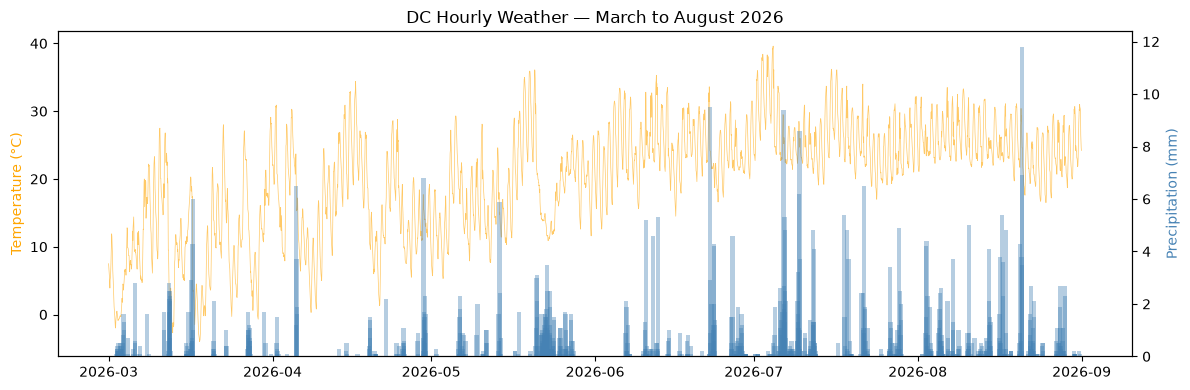

In [23]:
# Quick visual check — temperature and precipitation over the period
fig, ax1 = plt.subplots(figsize=(12, 4))

ax1.plot(df_weather.index, df_weather["temperature_2m"], color="orange", alpha=0.6, linewidth=0.5, label="Temp (°C)")
ax1.set_ylabel("Temperature (°C)", color="orange")
ax1.set_title("DC Hourly Weather — March to August 2026")

ax2 = ax1.twinx()
ax2.bar(df_weather.index, df_weather["precipitation"], color="steelblue", alpha=0.4, linewidth=0, label="Precipitation (mm)")
ax2.set_ylabel("Precipitation (mm)", color="steelblue")

fig.tight_layout()
plt.show()

In [24]:
# Save weather data
os.makedirs("Weather Data", exist_ok=True)
weather_path = os.path.join("Weather Data", "dc_weather_hourly.csv")
df_weather.to_csv(weather_path)
print(f"Saved weather data to: {weather_path}")
print(f"Records: {len(df_weather)}")
print(f"File size: {os.path.getsize(weather_path) / 1024:.1f} KB")

Saved weather data to: Weather Data/dc_weather_hourly.csv
Records: 4416
File size: 179.0 KB
